In [5]:
# load dataset and check its size
import pandas as pd

df = pd.read_parquet("data/unified_core.parquet")

print(df.shape)

(114954, 35)


In [8]:
# no of columns
print(df.columns)

Index(['uid', 'source', 'period', 'date_posted', 'scrape_date', 'title',
       'description', 'description_core_llm', 'job_description_embedding',
       'company_name_effective', 'company_name_canonical', 'is_aggregator',
       'company_industry', 'company_size', 'is_swe', 'is_control',
       'skill_themes', 'role_families', 'seniority_final',
       'seniority_final_source', 'seniority_rule', 'seniority_rule_source',
       'seniority_native', 'yoe_extracted', 'yoe_min_years_llm', 'location',
       'city_extracted', 'state_normalized', 'metro_area',
       'is_remote_inferred', 'is_multi_location', 'date_flag',
       'ghost_assessment_llm', 'has_llm_extraction', 'has_llm_classification'],
      dtype='object')


In [9]:
# look at one job posting
df.head(1)

,uid,source,period,date_posted,scrape_date,title,description,description_core_llm,job_description_embedding,company_name_effective,...,location,city_extracted,state_normalized,metro_area,is_remote_inferred,is_multi_location,date_flag,ghost_assessment_llm,has_llm_extraction,has_llm_classification
0,arshkon_133130219,kaggle_arshkon,2024-04,2024-04-19,None,Software Engineer,None,"Education Bachelor's degree in software, math,...","[-0.025558472, -0.0138549805, -0.012191772, 0....",None,...,Los Angeles Metropolitan Area,Los Angeles Metropolitan Area,None,None,False,False,ok,realistic,True,True


In [10]:
# check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114954 entries, 0 to 114953
Data columns (total 35 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   uid                        114954 non-null  object 
 1   source                     114954 non-null  object 
 2   period                     114954 non-null  object 
 3   date_posted                56892 non-null   object 
 4   scrape_date                58726 non-null   object 
 5   title                      114954 non-null  object 
 6   description                58726 non-null   object 
 7   description_core_llm       114175 non-null  object 
 8   job_description_embedding  113958 non-null  object 
 9   company_name_effective     114829 non-null  object 
 10  company_name_canonical     114829 non-null  object 
 11  is_aggregator              114954 non-null  bool   
 12  company_industry           72637 non-null   object 
 13  company_size               13

In [11]:
# check missing values in each column
df.isnull().sum()

uid                               0
source                            0
period                            0
date_posted                   58062
scrape_date                   56228
title                             0
description                   56228
description_core_llm            779
job_description_embedding       996
company_name_effective          125
company_name_canonical          125
is_aggregator                     0
company_industry              42317
company_size                 101059
is_swe                            0
is_control                        0
skill_themes                  55317
role_families                 55317
seniority_final                   0
seniority_final_source            0
seniority_rule                    0
seniority_rule_source             0
seniority_native              11356
yoe_extracted                 46353
yoe_min_years_llm             32942
location                       2450
city_extracted                 5133
state_normalized            

In [12]:
# check if each job posting has a unique id
print("total rows:", len(df))
print("unique ids:", df["uid"].nunique())

total rows: 114954
unique ids: 114954


In [13]:
# check the most common job titles
df["title"].value_counts().head(15)

title
Senior Accountant           1650
Senior Software Engineer    1592
Software Engineer           1469
Registered Nurse            1108
Accounting Manager           945
Electrical Engineer          694
Data Engineer                684
Staff Accountant             683
Accountant                   669
Data Scientist               532
Mechanical Engineer          528
Financial Analyst            510
Senior Financial Analyst     496
Senior Data Engineer         474
Registered Nurse (RN)        431
Name: count, dtype: int64

In [14]:
# check the software and control job counts
print(df["is_swe"].value_counts())
print(df["is_control"].value_counts())

is_swe
True     60119
False    54835
Name: count, dtype: int64
is_control
False    59954
True     55000
Name: count, dtype: int64


In [15]:
# check how swe and control records overlap
pd.crosstab(df["is_swe"], df["is_control"])

is_control,False,True
is_swe,,
False,0,54835
True,59954,165


In [16]:
# check how many jobs are in each period
df["period"].value_counts().sort_index()

period
2024-01    42208
2024-04    14020
2026-03    24716
2026-04    34010
Name: count, dtype: int64

In [17]:
# check ai job classification counts
df["has_llm_classification"].value_counts()

has_llm_classification
True    114954
Name: count, dtype: int64

In [18]:
# check the ai classification values
df["ghost_assessment_llm"].value_counts(dropna=False)

ghost_assessment_llm
realistic       110706
inflated          3805
ghost_likely       443
Name: count, dtype: int64

In [19]:
# check the role categories
df["role_families"].value_counts(dropna=False).head(20)

role_families
None                                               55317
[backend_api]                                       5919
[data_engineer]                                     3559
[embedded]                                          3464
[devops_sre_platform]                               3301
[qa_test]                                           2977
[software_engineer_general]                         2495
[data_analytics]                                    1978
[frontend_web]                                      1464
[mobile]                                            1355
[security]                                           906
[ml_engineer]                                        905
[legacy_specialist]                                  810
[ai_llm_engineer]                                    581
[solutions_field]                                    532
[infra_ops_admin]                                    323
[research]                                            91
[people_manager] 

In [20]:
# check the most common skill groups
df["skill_themes"].value_counts(dropna=False).head(20)

skill_themes
None                                                                                       55317
[verification]                                                                              3265
[performance]                                                                               1970
[process_scaffolding]                                                                       1136
[context_infrastructure]                                                                     674
[legacy_stack]                                                                               586
[orchestration]                                                                              536
[mentorship]                                                                                 472
[people_management]                                                                           43
[]                                                                                             1
[]               

In [21]:
# check the seniority levels
df["seniority_final"].value_counts()

seniority_final
unknown       64607
mid-senior    40182
entry          8462
director       1178
associate       525
Name: count, dtype: int64

In [23]:
# check the years of experience data
df["yoe_extracted"].describe()

count    68601.000000
mean         4.392749
std          2.921283
min          1.000000
25%          2.000000
50%          4.000000
75%          5.000000
max         20.000000
Name: yoe_extracted, dtype: float64

In [24]:
# see how experience years are distributed
df["yoe_extracted"].value_counts().sort_index()

yoe_extracted
1.0      9698
2.0     11285
3.0     11257
4.0      4983
5.0     14743
6.0      3025
7.0      3568
8.0      4158
9.0       442
10.0     3703
11.0       86
12.0      694
13.0       66
14.0      168
15.0      485
16.0       55
17.0        9
18.0       24
19.0        1
20.0      151
Name: count, dtype: int64

In [29]:
# look at a few ai and ml roles
df[df["role_families"]
.str.contains("ai_llm_engineer|ml_engineer", na=False)][["title",
"role_families"]].head(10)

,title,role_families


In [30]:
# check how many ai and ml roles we found
print(df["role_families"].str.contains("ai_llm_engineer|ml_engineer", na=False).sum())

0


In [31]:
# check the role family data type
print(type(df["role_families"].dropna().iloc[0]))
print(df["role_families"].dropna().iloc[0])

<class 'numpy.ndarray'>
['software_engineer_general']


In [32]:
# find jobs labeled as ai or ml roles
ai_ml = df[df["role_families"].apply(
    lambda x: x is not None and ("ai_llm_engineer" in x or "ml_engineer" in x)
)]

ai_ml[["title", "role_families"]].head(10)

,title,role_families
49,Senior Machine Learning Research Engineer,"[ml_engineer, research]"
98,Generative AI Engineer,"[ai_llm_engineer, ml_engineer, solutions_field]"
355,AI Solution Architect,"[ai_llm_engineer, data_engineer, devops_sre_pl..."
656,Developer,[ml_engineer]
673,AI/ML Developer,"[data_engineer, devops_sre_platform, ml_engineer]"
795,Sr. Data Scientist - IoT and Manufacturing,[ml_engineer]
819,Senior Data Scientist - Forecasting,"[data_analytics, ml_engineer]"
862,MLE/AI Engineer Summer Intern,"[ml_engineer, research]"
925,Gen AI Enginner,[ai_llm_engineer]
979,Software Engineer Intern,[ml_engineer]


In [33]:
# count ai and ml related jobs
print("ai/ml jobs:", len(ai_ml))
print("share of all jobs:", round(len(ai_ml) / len(df) * 100, 2), "%")

ai/ml jobs: 8161
share of all jobs: 7.1 %


In [34]:
# compare ml and ai/llm jobs
print("ml jobs:", df["role_families"].apply(
    lambda x: x is not None and "ml_engineer" in x
).sum())

print("ai/llm jobs:", df["role_families"].apply(
    lambda x: x is not None and "ai_llm_engineer" in x
).sum())

ml jobs: 4321
ai/llm jobs: 5218


In [35]:
# check jobs that belong to both ai and ml
both_ai_ml = df["role_families"].apply(
    lambda x: x is not None and "ai_llm_engineer" in x and "ml_engineer" in x
).sum()

print("both ai/ml:", both_ai_ml)

both ai/ml: 1378


In [36]:
# separate ai and ml jobs into clear groups
def classify_ai_ml(x):
    if x is None:
        return "other"
    has_ml = "ml_engineer" in x
    has_ai = "ai_llm_engineer" in x
    
    if has_ml and has_ai:
        return "both"
    elif has_ml:
        return "ml_only"
    elif has_ai:
        return "ai_llm_only"
    return "other"

df["ai_ml_group"] = df["role_families"].apply(classify_ai_ml)

df["ai_ml_group"].value_counts()

ai_ml_group
other          106793
ai_llm_only      3840
ml_only          2943
both             1378
Name: count, dtype: int64

In [37]:
# compare ai/ml share across periods
pd.crosstab(
    df["period"],
    df["ai_ml_group"],
    normalize="index"
).round(4) * 100

ai_ml_group,ai_llm_only,both,ml_only,other
period,,,,
2024-01,0.35,0.26,1.56,97.83
2024-04,0.55,0.39,1.48,97.58
2026-03,5.92,1.93,3.55,88.59
2026-04,6.32,2.17,3.53,87.98


In [38]:
# calculate ai/ml jobs and share by period
ai_ml_by_period = (
    df.assign(is_ai_ml=df["ai_ml_group"] != "other")
    .groupby("period")["is_ai_ml"]
    .agg(["sum", "count"])
)

ai_ml_by_period["share_pct"] = (
    ai_ml_by_period["sum"] / ai_ml_by_period["count"] * 100
).round(2)

ai_ml_by_period

,sum,count,share_pct
period,,,
2024-01,915,42208,2.17
2024-04,339,14020,2.42
2026-03,2820,24716,11.41
2026-04,4087,34010,12.02


In [39]:
# compare ai/ml role mix across periods
ai_ml_df = df[df["ai_ml_group"] != "other"]

pd.crosstab(
    ai_ml_df["period"],
    ai_ml_df["ai_ml_group"],
    normalize="index"
).round(4) * 100

ai_ml_group,ai_llm_only,both,ml_only
period,,,
2024-01,16.17,11.91,71.91
2024-04,22.71,15.93,61.36
2026-03,51.91,16.95,31.13
2026-04,52.63,18.03,29.34


In [40]:
# check ai/ml job counts by period
pd.crosstab(df["period"], df["ai_ml_group"])

ai_ml_group,ai_llm_only,both,ml_only,other
period,,,,
2024-01,148,109,658,41293
2024-04,77,54,208,13681
2026-03,1464,478,878,21896
2026-04,2151,737,1199,29923


In [41]:
# check job sources across periods
pd.crosstab(df["period"], df["source"])

source,kaggle_arshkon,kaggle_asaniczka,scraped
period,,,
2024-01,0,42208,0
2024-04,14020,0,0
2026-03,0,0,24716
2026-04,0,0,34010


In [42]:
# keep the 2026 job postings for the main analysis
df_2026 = df[df["period"].isin(["2026-03", "2026-04"])].copy()

print(df_2026.shape)

(58726, 36)


In [43]:
# mark ai/ml related jobs
df_2026["is_ai_ml"] = df_2026["ai_ml_group"] != "other"

print(df_2026["is_ai_ml"].value_counts())

is_ai_ml
False    51819
True      6907
Name: count, dtype: int64


In [44]:
# compare ai/ml share in march and april 2026
pd.crosstab(
    df_2026["period"],
    df_2026["is_ai_ml"],
    normalize="index"
).round(4) * 100

is_ai_ml,False,True
period,,
2026-03,88.59,11.41
2026-04,87.98,12.02


In [45]:
# compare ai/ml role mix in 2026
pd.crosstab(
    df_2026[df_2026["is_ai_ml"]]["period"],
    df_2026[df_2026["is_ai_ml"]]["ai_ml_group"],
    normalize="index"
).round(4) * 100

ai_ml_group,ai_llm_only,both,ml_only
period,,,
2026-03,51.91,16.95,31.13
2026-04,52.63,18.03,29.34


In [46]:
# check the most common ai/ml job titles
ai_ml_df["title"].value_counts().head(20)

title
Data Scientist                      231
Machine Learning Engineer           211
AI Engineer                         155
Senior Data Scientist               145
Senior Software Engineer            141
Senior Machine Learning Engineer    130
Software Engineer                   114
Artificial Intelligence Engineer    107
Senior AI Engineer                   70
Principal Software Engineer          58
AI/ML Engineer                       50
Lead Data Scientist                  50
Full Stack Engineer                  49
Generative AI Engineer               38
Staff Machine Learning Engineer      35
Lead Machine Learning Engineer       33
Lead Software Engineer               32
Lead AI Engineer                     31
Principal Data Scientist             30
Founding Engineer                    27
Name: count, dtype: int64

In [47]:
# create the 2026 ai/ml job dataset
ai_ml_2026 = df_2026[df_2026["is_ai_ml"]].copy()

print(ai_ml_2026.shape)

(6907, 37)


In [48]:
# check the most common ai/ml job titles in 2026
ai_ml_2026["title"].value_counts().head(15)

title
Data Scientist                      180
Machine Learning Engineer           157
AI Engineer                         150
Senior Software Engineer            123
Software Engineer                   104
Artificial Intelligence Engineer     88
Senior Data Scientist                88
Senior Machine Learning Engineer     78
Senior AI Engineer                   63
Principal Software Engineer          56
AI/ML Engineer                       49
Full Stack Engineer                  47
Lead Software Engineer               30
Generative AI Engineer               30
Staff Machine Learning Engineer      29
Name: count, dtype: int64

In [49]:
# check seniority levels in ai/ml jobs
ai_ml_2026["seniority_final"].value_counts()

seniority_final
mid-senior    3439
unknown       2994
entry          376
director        77
associate       21
Name: count, dtype: int64

In [50]:
# compare seniority for ai/ml and other jobs
known_seniority = df_2026[df_2026["seniority_final"] != "unknown"]

pd.crosstab(
    known_seniority["is_ai_ml"],
    known_seniority["seniority_final"],
    normalize="index"
).round(4) * 100

seniority_final,associate,director,entry,mid-senior
is_ai_ml,,,,
False,1.32,2.62,15.62,80.45
True,0.54,1.97,9.61,87.89


In [51]:
# compare experience requirements for ai/ml and other jobs
df_2026.groupby("is_ai_ml")["yoe_extracted"].describe()

,count,mean,std,min,25%,50%,75%,max
is_ai_ml,,,,,,,,
False,31980.0,4.415604,2.827317,1.0,2.0,4.0,5.0,20.0
True,4485.0,4.797770,2.609151,1.0,3.0,5.0,6.0,17.0


In [52]:
# compare experience across ai/ml role groups
ai_ml_2026.groupby("ai_ml_group")["yoe_extracted"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
ai_ml_group,,,
ai_llm_only,2339,4.91,5.0
both,787,4.84,5.0
ml_only,1359,4.58,4.0


In [53]:
# compare experience across ai/ml role groups
ai_ml_2026.groupby("ai_ml_group")["yoe_extracted"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
ai_ml_group,,,
ai_llm_only,2339,4.91,5.0
both,787,4.84,5.0
ml_only,1359,4.58,4.0


In [54]:
# check available skill data
print(ai_ml_2026["skill_themes"].notna().sum())

6907


In [55]:
# count individual skills in ai/ml jobs
skills = ai_ml_2026["skill_themes"].explode()

skills.value_counts()

skill_themes
verification              5189
orchestration             3519
performance               3174
context_infrastructure    2964
mentorship                2106
process_scaffolding       1800
legacy_stack               227
people_management          119
Name: count, dtype: int64

In [56]:
# compare skills across ai/ml groups
skill_group = ai_ml_2026.explode("skill_themes")

pd.crosstab(
    skill_group["ai_ml_group"],
    skill_group["skill_themes"],
    normalize="index"
).round(3) * 100

skill_themes,context_infrastructure,legacy_stack,mentorship,orchestration,people_management,performance,process_scaffolding,verification
ai_ml_group,,,,,,,,
ai_llm_only,15.8,1.5,10.7,22.5,0.5,15.1,9.6,24.4
both,13.7,0.7,11.4,18.9,0.7,17.0,8.6,29.0
ml_only,16.2,0.7,11.7,7.9,0.8,20.3,9.6,32.8


In [57]:
# check how many ai/ml jobs mention each skill
skill_counts = (
    ai_ml_2026.explode("skill_themes")
    .groupby("skill_themes")["uid"]
    .nunique()
    .sort_values(ascending=False)
)

skill_counts

skill_themes
verification              5189
orchestration             3519
performance               3174
context_infrastructure    2964
mentorship                2106
process_scaffolding       1800
legacy_stack               227
people_management          119
Name: uid, dtype: int64

In [59]:
# compare how many jobs mention each skill
skill_group = ai_ml_2026[
    ai_ml_2026["ai_ml_group"].isin(["ai_llm_only", "ml_only"])
].explode("skill_themes")

skill_counts = (
    skill_group.groupby(
        ["ai_ml_group", "skill_themes"]
    )["uid"]
    .nunique()
    .unstack(0)
)

skill_counts

ai_ml_group,ai_llm_only,ml_only
skill_themes,,
context_infrastructure,1781,725
legacy_stack,171,31
mentorship,1201,524
orchestration,2530,356
people_management,58,37
performance,1696,908
process_scaffolding,1084,429
verification,2747,1470


In [60]:
# compare skill demand by job group
skill_pct = skill_counts.div(
    skill_counts.sum(axis=0), axis=1
).round(3) * 100

skill_pct

ai_ml_group,ai_llm_only,ml_only
skill_themes,,
context_infrastructure,15.8,16.2
legacy_stack,1.5,0.7
mentorship,10.7,11.7
orchestration,22.5,7.9
people_management,0.5,0.8
performance,15.1,20.3
process_scaffolding,9.6,9.6
verification,24.4,32.8


In [61]:
# calculate skill share within each job group
group_sizes = ai_ml_2026["ai_ml_group"].value_counts()

skill_pct = (
    skill_counts.div(group_sizes.loc[skill_counts.columns], axis=1)
    .round(3) * 100
)

skill_pct

ai_ml_group,ai_llm_only,ml_only
skill_themes,,
context_infrastructure,49.3,34.9
legacy_stack,4.7,1.5
mentorship,33.2,25.2
orchestration,70.0,17.1
people_management,1.6,1.8
performance,46.9,43.7
process_scaffolding,30.0,20.7
verification,76.0,70.8


In [62]:
# rank skills by the difference between ai/llm and ml roles
skill_diff = (
    skill_pct["ai_llm_only"] - skill_pct["ml_only"]
).sort_values(ascending=False)

skill_diff

skill_themes
orchestration             52.9
context_infrastructure    14.4
process_scaffolding        9.3
mentorship                 8.0
verification               5.2
legacy_stack               3.2
performance                3.2
people_management         -0.2
dtype: float64

In [63]:
# compare remote work in ai/ml roles
pd.crosstab(
    ai_ml_2026["ai_ml_group"],
    ai_ml_2026["is_remote_inferred"],
    normalize="index"
).round(3) * 100

is_remote_inferred,False
ai_ml_group,
ai_llm_only,100.0
both,100.0
ml_only,100.0


In [65]:
# check remote status across all 2026 jobs
df_2026["is_remote_inferred"].value_counts()

is_remote_inferred
False    58726
Name: count, dtype: int64

In [66]:
# check the top hiring locations
ai_ml_2026["metro_area"].value_counts().head(15)

metro_area
San Francisco Bay Area     1197
Seattle Metro               435
Washington DC Metro         388
New York City Metro         369
Salt Lake City Metro        363
Dallas-Fort Worth Metro     303
Boston Metro                237
Los Angeles Metro           200
Atlanta Metro               185
Charlotte Metro             170
Chicago Metro               152
Austin Metro                131
Houston Metro               102
Philadelphia Metro           97
Phoenix Metro                92
Name: count, dtype: int64

In [67]:
# check available location data
print(ai_ml_2026["metro_area"].notna().sum())
print(ai_ml_2026["metro_area"].isna().sum())

5082
1825


In [68]:
# check location coverage by ai/ml group
ai_ml_2026.groupby("ai_ml_group")["metro_area"].apply(
    lambda x: x.notna().mean() * 100
).round(2)

ai_ml_group
ai_llm_only    74.30
both           73.17
ml_only        72.56
Name: metro_area, dtype: float64

In [69]:
# compare ai/ml hiring across locations
metro_analysis = (
    df_2026[df_2026["metro_area"].notna()]
    .groupby("metro_area")
    .agg(
        total_jobs=("uid", "count"),
        ai_ml_jobs=("is_ai_ml", "sum")
    )
)

metro_analysis["ai_ml_share"] = (
    metro_analysis["ai_ml_jobs"] / metro_analysis["total_jobs"] * 100
).round(2)

metro_analysis.sort_values("ai_ml_jobs", ascending=False).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share
metro_area,,,
San Francisco Bay Area,5525,1197,21.67
Seattle Metro,2501,435,17.39
Washington DC Metro,3740,388,10.37
New York City Metro,2680,369,13.77
Salt Lake City Metro,2416,363,15.02
Dallas-Fort Worth Metro,2870,303,10.56
Boston Metro,2440,237,9.71
Los Angeles Metro,2649,200,7.55
Atlanta Metro,1973,185,9.38


In [70]:
# find ai/ml focused markets with enough job postings
metro_priority = metro_analysis[metro_analysis["total_jobs"] >= 500]

metro_priority.sort_values("ai_ml_share", ascending=False).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share
metro_area,,,
San Francisco Bay Area,5525,1197,21.67
Seattle Metro,2501,435,17.39
Salt Lake City Metro,2416,363,15.02
New York City Metro,2680,369,13.77
Dallas-Fort Worth Metro,2870,303,10.56
Washington DC Metro,3740,388,10.37
Charlotte Metro,1653,170,10.28
Boston Metro,2440,237,9.71
San Diego Metro,774,75,9.69


In [71]:
# calculate the overall ai/ml share for known locations
metro_baseline = (
    df_2026[df_2026["metro_area"].notna()]["is_ai_ml"].mean() * 100
)

print(round(metro_baseline, 2), "%")

10.89 %


In [72]:
# compare each market with the ai/ml benchmark
metro_priority["benchmark_gap"] = (
    metro_priority["ai_ml_share"] - metro_baseline
)

metro_priority.sort_values(
    "benchmark_gap",
    ascending=False
).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share,benchmark_gap
metro_area,,,,
San Francisco Bay Area,5525,1197,21.67,10.77751
Seattle Metro,2501,435,17.39,6.49751
Salt Lake City Metro,2416,363,15.02,4.12751
New York City Metro,2680,369,13.77,2.87751
Dallas-Fort Worth Metro,2870,303,10.56,-0.33249
Washington DC Metro,3740,388,10.37,-0.52249
Charlotte Metro,1653,170,10.28,-0.61249
Boston Metro,2440,237,9.71,-1.18249
San Diego Metro,774,75,9.69,-1.20249


In [73]:
# check the top ai/ml hiring companies
ai_ml_2026["company_name_canonical"].value_counts().head(15)

company_name_canonical
Jobs via Dice                213
Google                       158
Microsoft                    112
JPMorgan Chase & Co.          92
Capital One                   78
Amazon                        74
Amazon Web Services (AWS)     60
Uber                          59
Wells Fargo                   55
TikTok                        54
Walmart                       54
Booz Allen Hamilton           49
Intuit                        46
Adobe                         42
ByteDance                     38
Name: count, dtype: int64

In [74]:
# check top ai/ml employers without aggregators
real_companies = ai_ml_2026[ai_ml_2026["is_aggregator"] == False]

real_companies["company_name_canonical"].value_counts().head(15)

company_name_canonical
Google                       158
Microsoft                    112
JPMorgan Chase & Co.          92
Capital One                   77
Amazon                        74
Amazon Web Services (AWS)     60
Uber                          59
Wells Fargo                   55
TikTok                        54
Walmart                       54
Booz Allen Hamilton           49
Intuit                        46
Adobe                         42
ByteDance                     38
hackajob                      37
Name: count, dtype: int64

In [75]:
# find companies with a high ai/ml hiring share
company_analysis = (
    df_2026[df_2026["company_name_canonical"].notna()]
    .groupby("company_name_canonical")
    .agg(
        total_jobs=("uid", "count"),
        ai_ml_jobs=("is_ai_ml", "sum")
    )
)

company_analysis["ai_ml_share"] = (
    company_analysis["ai_ml_jobs"] / company_analysis["total_jobs"] * 100
).round(2)

company_analysis[
    company_analysis["total_jobs"] >= 100
].sort_values("ai_ml_share", ascending=False).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share
company_name_canonical,,,
Microsoft,300,112,37.33
Adobe,120,42,35.00
TikTok,157,54,34.39
Uber,172,59,34.30
Capital One,229,78,34.06
Intuit,147,46,31.29
Walmart,175,54,30.86
TikTok USDS Joint Venture,106,30,28.30
Tata Consultancy Services,109,28,25.69


In [76]:
# rank companies by ai/ml hiring opportunity
company_analysis["priority_score"] = (
    company_analysis["ai_ml_jobs"] * company_analysis["ai_ml_share"] / 100
)

company_analysis[
    company_analysis["total_jobs"] >= 100
].sort_values("priority_score", ascending=False).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share,priority_score
company_name_canonical,,,,
Microsoft,300,112,37.33,41.8096
Google,619,158,25.53,40.3374
Capital One,229,78,34.06,26.5668
Jobs via Dice,1754,213,12.14,25.8582
Uber,172,59,34.30,20.2370
TikTok,157,54,34.39,18.5706
JPMorgan Chase & Co.,503,92,18.29,16.8268
Walmart,175,54,30.86,16.6644
Adobe,120,42,35.00,14.7000


In [77]:
# compare real companies by ai/ml volume and share
company_analysis = (
    df_2026[
        (df_2026["is_aggregator"] == False) &
        (df_2026["company_name_canonical"].notna())
    ]
    .groupby("company_name_canonical")
    .agg(
        total_jobs=("uid", "count"),
        ai_ml_jobs=("is_ai_ml", "sum")
    )
)

company_analysis["ai_ml_share"] = (
    company_analysis["ai_ml_jobs"] / company_analysis["total_jobs"] * 100
).round(2)

company_analysis[
    company_analysis["total_jobs"] >= 100
].sort_values("ai_ml_jobs", ascending=False).head(15)

,total_jobs,ai_ml_jobs,ai_ml_share
company_name_canonical,,,
Google,619,158,25.53
Microsoft,296,112,37.84
JPMorgan Chase & Co.,503,92,18.29
Capital One,227,77,33.92
Amazon,380,74,19.47
Amazon Web Services (AWS),325,60,18.46
Uber,172,59,34.30
Wells Fargo,222,55,24.77
Walmart,175,54,30.86


In [81]:
# check if duckdb is installed
import duckdb
print(duckdb.__version__)

1.5.6


In [82]:
# connect python to duckdb
import duckdb

con = duckdb.connect()

In [83]:
# test sql access to the dataset
result = con.execute("""
    select count(*) as total_jobs
    from read_parquet('data/unified_core.parquet')
""").fetchone()

print(result[0])

114954


In [84]:
# create a duckdb database file for sql
duckdb.connect("ai_hiring.duckdb").close()

In [1]:
# find the full path of the duckdb file
import os
print(os.path.abspath("ai_hiring.duckdb"))

c:\Anisha Maria Lobo(college)\PROJECTSSSSSSSSSSSSSSSSS\AI_Hiring_Intelligence\ai_hiring.duckdb


In [1]:
# connect to duckdb and check the march and april job counts
import duckdb

con = duckdb.connect()

con.execute("""
    select
        period,
        count(*) as total_jobs
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by period
    order by period
""").df()

,period,total_jobs
0,2026-03,24716
1,2026-04,34010


In [7]:
# run the hiring share query from our sql file
sql = open("sql/hiring_analysis.sql", encoding="utf-8").read()
queries = [q.strip() for q in sql.split(";") if q.strip()]
con.execute(queries[1]).df()

,period,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,2026-03,24716,2820,11.41
1,2026-04,34010,4087,12.02


In [8]:
# find the most common ai/ml job titles
con.execute("""
    select
        title,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
      and (
          lower(title) like '%ai engineer%'
          or lower(title) like '%machine learning%'
          or lower(title) like '%data scientist%'
          or lower(title) like '%artificial intelligence%'
          or lower(title) like '%llm%'
      )
    group by title
    order by job_count desc
    limit 15
""").df()

,title,job_count
0,Data Scientist,383
1,Machine Learning Engineer,160
2,AI Engineer,157
3,Senior Data Scientist,155
4,Artificial Intelligence Engineer,93
5,Senior Machine Learning Engineer,78
6,Senior AI Engineer,66
7,Staff Data Scientist,35
8,Lead Data Scientist,34
9,Principal Data Scientist,31


In [9]:
# compare ai/ml job titles by month
con.execute("""
    select
        period,
        title,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
      and (
          lower(title) like '%ai engineer%'
          or lower(title) like '%machine learning%'
          or lower(title) like '%data scientist%'
          or lower(title) like '%artificial intelligence%'
          or lower(title) like '%llm%'
      )
    group by period, title
    order by title, period
""").df()

,period,title,job_count
0,2026-03,"#Senior Embedded Software Engineer, Cloud Edge...",1
1,2026-03,(General Hire) Machine Learning Engineer Gradu...,1
2,2026-03,(General Hire) Machine Learning Engineer Inter...,1
3,2026-04,(General Hire) Machine Learning Engineer Inter...,1
4,2026-03,(General Hire) Machine Learning Engineer Inter...,1
...,...,...,...
2411,2026-03,junior software developer/Machine learning eng...,1
2412,2026-04,"lead data scientist - Seattle, WA",1
2413,2026-04,mid-level Generative AI / LLM-focused Software...,1
2414,2026-03,"senior data scientist - Pricing (Seattle, WA)",1


In [10]:
# get the top 15 ai/ml job titles by month
con.execute("""
    with classified_jobs as (
        select
            period,
            title,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1
                else 0
            end as is_ai_ml
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
    )
    select
        period,
        title,
        count(*) as job_count
    from classified_jobs
    where is_ai_ml = 1
    group by period, title
    order by period, job_count desc
    limit 30
""").df()

,period,title,job_count
0,2026-03,Data Scientist,63
1,2026-03,Machine Learning Engineer,60
2,2026-03,AI Engineer,57
3,2026-03,Senior Software Engineer,55
4,2026-03,Senior Data Scientist,37
5,2026-03,Software Engineer,35
6,2026-03,Senior Machine Learning Engineer,34
7,2026-03,Artificial Intelligence Engineer,34
8,2026-03,Principal Software Engineer,26
9,2026-03,Senior AI Engineer,25


In [15]:
# check the actual experience and role column names
con.execute("""
    describe
    select *
    from read_parquet('data/unified_core.parquet')
""").df().query("column_name.str.contains('experience|role_famil', case=False)", engine="python")

,column_name,column_type,null,key,default,extra
17,role_families,VARCHAR[],YES,None,None,None


In [16]:
# inspect experience-related columns
con.execute("""
    describe
    select *
    from read_parquet('data/unified_core.parquet')
""").df().query("column_name.str.contains('exp|seniority', case=False)", engine="python")

,column_name,column_type,null,key,default,extra
18,seniority_final,VARCHAR,YES,None,None,None
19,seniority_final_source,VARCHAR,YES,None,None,None
20,seniority_rule,VARCHAR,YES,None,None,None
21,seniority_rule_source,VARCHAR,YES,None,None,None
22,seniority_native,VARCHAR,YES,None,None,None


In [17]:
# check available columns for experience requirements
con.execute("""
    describe
    select *
    from read_parquet('data/unified_core.parquet')
""").df().query("column_name.str.contains('experience|years|seniority', case=False)", engine="python")

,column_name,column_type,null,key,default,extra
18,seniority_final,VARCHAR,YES,None,None,None
19,seniority_final_source,VARCHAR,YES,None,None,None
20,seniority_rule,VARCHAR,YES,None,None,None
21,seniority_rule_source,VARCHAR,YES,None,None,None
22,seniority_native,VARCHAR,YES,None,None,None
24,yoe_min_years_llm,BIGINT,YES,None,None,None


In [18]:
# compare minimum experience requirements for ai/ml and other roles
con.execute("""
    select
        case
            when list_contains(role_families, 'ai_llm_engineer')
                 or list_contains(role_families, 'ml_engineer')
            then 'AI/ML'
            else 'Other'
        end as job_group,
        count(*) as total_jobs,
        count(yoe_min_years_llm) as jobs_with_experience_data,
        round(avg(yoe_min_years_llm), 2) as avg_min_experience_years,
        median(yoe_min_years_llm) as median_min_experience_years
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by job_group
    order by job_group
""").df()

,job_group,total_jobs,jobs_with_experience_data,avg_min_experience_years,median_min_experience_years
0,AI/ML,6907,5292,5.19,5.0
1,Other,51819,38505,4.53,4.0


In [19]:
# compare seniority levels in ai/ml and other jobs
con.execute("""
    select
        case
            when list_contains(role_families, 'ai_llm_engineer')
                 or list_contains(role_families, 'ml_engineer')
            then 'AI/ML'
            else 'Other'
        end as job_group,
        seniority_final,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by job_group, seniority_final
    order by job_group, job_count desc
""").df()

,job_group,seniority_final,job_count
0,AI/ML,mid-senior,3439
1,AI/ML,unknown,2994
2,AI/ML,entry,376
3,AI/ML,director,77
4,AI/ML,associate,21
5,Other,unknown,29641
6,Other,mid-senior,17842
7,Other,entry,3464
8,Other,director,580
9,Other,associate,292


In [20]:
# compare ai/ml skill themes
con.execute("""
    select
        case
            when list_contains(role_families, 'ai_llm_engineer')
            then 'AI/LLM'
            when list_contains(role_families, 'ml_engineer')
            then 'ML'
            else 'Other'
        end as role_group,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by role_group
    order by job_count desc
""").df()

,role_group,job_count
0,Other,51819
1,AI/LLM,4830
2,ML,2077


In [21]:
# compare key skill themes across ai/llm and ml roles
con.execute("""
    select
        case
            when list_contains(role_families, 'ai_llm_engineer')
                 and not list_contains(role_families, 'ml_engineer')
                then 'AI/LLM only'
            when list_contains(role_families, 'ml_engineer')
                 and not list_contains(role_families, 'ai_llm_engineer')
                then 'ML only'
            when list_contains(role_families, 'ai_llm_engineer')
                 and list_contains(role_families, 'ml_engineer')
                then 'Both'
            else 'Other'
        end as role_group,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by role_group
    order by job_count desc
""").df()

,role_group,job_count
0,Other,51819
1,AI/LLM only,3615
2,ML only,2077
3,Both,1215


In [23]:
# compare skill themes across ai/llm-only and ml-only jobs
con.execute("""
    with role_groups as (
        select
            uid,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     and not list_contains(role_families, 'ml_engineer')
                    then 'AI/LLM only'
                when list_contains(role_families, 'ml_engineer')
                     and not list_contains(role_families, 'ai_llm_engineer')
                    then 'ML only'
            end as role_group,
            skill_themes
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
    ),
    expanded_skills as (
        select
            r.role_group,
            unnest(r.skill_themes) as skill_theme,
            r.uid
        from role_groups r
        where r.role_group is not null
    ),
    skill_counts as (
        select
            role_group,
            skill_theme,
            count(distinct uid) as jobs_with_skill
        from expanded_skills
        group by role_group, skill_theme
    ),
    group_totals as (
        select
            role_group,
            count(distinct uid) as total_jobs
        from role_groups
        where role_group is not null
        group by role_group
    )
    select
        s.role_group,
        s.skill_theme,
        s.jobs_with_skill,
        round(100.0 * s.jobs_with_skill / g.total_jobs, 2) as skill_share_pct
    from skill_counts s
    join group_totals g using (role_group)
    order by s.skill_theme, s.role_group
""").df()

,role_group,skill_theme,jobs_with_skill,skill_share_pct
0,AI/LLM only,context_infrastructure,1781,49.27
1,ML only,context_infrastructure,725,34.91
2,AI/LLM only,legacy_stack,171,4.73
3,ML only,legacy_stack,31,1.49
4,AI/LLM only,mentorship,1201,33.22
5,ML only,mentorship,524,25.23
6,AI/LLM only,orchestration,2530,69.99
7,ML only,orchestration,356,17.14
8,AI/LLM only,people_management,58,1.60
9,ML only,people_management,37,1.78


In [25]:
# rank skill themes by their difference between ai/llm and ml jobs
con.execute("""
    with role_groups as (
        select
            uid,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     and not list_contains(role_families, 'ml_engineer')
                    then 'AI/LLM only'
                when list_contains(role_families, 'ml_engineer')
                     and not list_contains(role_families, 'ai_llm_engineer')
                    then 'ML only'
            end as role_group,
            skill_themes
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
    ),
    expanded_skills as (
        select
            uid,
            role_group,
            unnest(skill_themes) as skill_theme
        from role_groups
        where role_group is not null
    ),
    skill_counts as (
        select
            role_group,
            skill_theme,
            count(distinct uid) as jobs_with_skill
        from expanded_skills
        group by role_group, skill_theme
    ),
    group_totals as (
        select
            role_group,
            count(distinct uid) as total_jobs
        from role_groups
        where role_group is not null
        group by role_group
    ),
    skill_shares as (
        select
            s.skill_theme,
            s.role_group,
            round(100.0 * s.jobs_with_skill / g.total_jobs, 2) as skill_share_pct
        from skill_counts s
        join group_totals g using (role_group)
    )
    select
        skill_theme,
        max(case when role_group = 'AI/LLM only' then skill_share_pct end) as ai_llm_pct,
        max(case when role_group = 'ML only' then skill_share_pct end) as ml_pct,
        round(
            max(case when role_group = 'AI/LLM only' then skill_share_pct end)
            - max(case when role_group = 'ML only' then skill_share_pct end),
            2
        ) as difference_pp
    from skill_shares
    group by skill_theme
    order by difference_pp desc
""").df()

,skill_theme,ai_llm_pct,ml_pct,difference_pp
0,orchestration,69.99,17.14,52.85
1,context_infrastructure,49.27,34.91,14.36
2,process_scaffolding,29.99,20.65,9.34
3,mentorship,33.22,25.23,7.99
4,verification,75.99,70.78,5.21
5,legacy_stack,4.73,1.49,3.24
6,performance,46.92,43.72,3.20
7,people_management,1.60,1.78,-0.18


In [26]:
# compare ai/ml hiring share by metro area
con.execute("""
    with job_groups as (
        select
            metro_area,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1
                else 0
            end as is_ai_ml
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and metro_area is not null
    )
    select
        metro_area,
        count(*) as total_jobs,
        sum(is_ai_ml) as ai_ml_jobs,
        round(100.0 * sum(is_ai_ml) / count(*), 2) as ai_ml_share_pct
    from job_groups
    group by metro_area
    having count(*) >= 500
    order by ai_ml_share_pct desc
    limit 20
""").df()

,metro_area,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,San Francisco Bay Area,5525,1197.0,21.67
1,Seattle Metro,2501,435.0,17.39
2,Salt Lake City Metro,2416,363.0,15.02
3,New York City Metro,2680,369.0,13.77
4,Dallas-Fort Worth Metro,2870,303.0,10.56
5,Washington DC Metro,3740,388.0,10.37
6,Charlotte Metro,1653,170.0,10.28
7,Boston Metro,2440,237.0,9.71
8,San Diego Metro,774,75.0,9.69
9,Atlanta Metro,1973,185.0,9.38


In [30]:
# compare companies hiring for ai/ml roles
con.execute("""
    with job_groups as (
        select
            company_name_canonical as company,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1
                else 0
            end as is_ai_ml,
            coalesce(is_aggregator, false) as is_aggregator
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and company_name_canonical is not null
    )
    select
        company,
        count(*) as total_jobs,
        sum(is_ai_ml) as ai_ml_jobs,
        round(100.0 * sum(is_ai_ml) / count(*), 2) as ai_ml_share_pct
    from job_groups
    where is_aggregator = false
    group by company
    having count(*) >= 100
    order by ai_ml_share_pct desc, ai_ml_jobs desc
    limit 20
""").df()

,company,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,Microsoft,296,112.0,37.84
1,Adobe,120,42.0,35.00
2,TikTok,157,54.0,34.39
3,Uber,172,59.0,34.30
4,Capital One,227,77.0,33.92
5,Intuit,144,46.0,31.94
6,Walmart,175,54.0,30.86
7,TikTok USDS Joint Venture,106,30.0,28.30
8,Google,619,158.0,25.53
9,Wells Fargo,222,55.0,24.77


In [31]:
# compare remote and onsite hiring patterns
con.execute("""
    select
        is_remote_inferred,
        count(*) as total_jobs,
        sum(
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1 else 0
            end
        ) as ai_ml_jobs,
        round(
            100.0 * sum(
                case
                    when list_contains(role_families, 'ai_llm_engineer')
                         or list_contains(role_families, 'ml_engineer')
                    then 1 else 0
                end
            ) / count(*),
            2
        ) as ai_ml_share_pct
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by is_remote_inferred
    order by total_jobs desc
""").df()

,is_remote_inferred,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,False,58726,6907.0,11.76


In [32]:
# check how many jobs have missing metro locations
con.execute("""
    select
        case
            when metro_area is null then 'Missing location'
            else 'Location available'
        end as location_status,
        count(*) as total_jobs,
        sum(
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1 else 0
            end
        ) as ai_ml_jobs
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by location_status
    order by total_jobs desc
""").df()

,location_status,total_jobs,ai_ml_jobs
0,Location available,46656,5082.0
1,Missing location,12070,1825.0


In [33]:
# compare ai/ml hiring share by location completeness
con.execute("""
    select
        case
            when metro_area is null then 'Missing location'
            else 'Location available'
        end as location_status,
        count(*) as total_jobs,
        sum(
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1 else 0
            end
        ) as ai_ml_jobs,
        round(
            100.0 * sum(
                case
                    when list_contains(role_families, 'ai_llm_engineer')
                         or list_contains(role_families, 'ml_engineer')
                    then 1 else 0
                end
            ) / count(*),
            2
        ) as ai_ml_share_pct
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by location_status
    order by total_jobs desc
""").df()

,location_status,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,Location available,46656,5082.0,10.89
1,Missing location,12070,1825.0,15.12


In [34]:
# find companies with the highest ai/ml hiring share
con.execute("""
    with jobs as (
        select
            company_name_canonical as company,
            case
                when list_contains(role_families, 'ai_llm_engineer')
                     or list_contains(role_families, 'ml_engineer')
                then 1 else 0
            end as is_ai_ml,
            coalesce(is_aggregator, false) as is_aggregator
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and company_name_canonical is not null
    )
    select
        company,
        count(*) as total_jobs,
        sum(is_ai_ml) as ai_ml_jobs,
        round(100.0 * sum(is_ai_ml) / count(*), 2) as ai_ml_share_pct
    from jobs
    where is_aggregator = false
    group by company
    having count(*) >= 100
    order by ai_ml_jobs desc
    limit 15
""").df()

,company,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,Google,619,158.0,25.53
1,Microsoft,296,112.0,37.84
2,JPMorgan Chase & Co.,503,92.0,18.29
3,Capital One,227,77.0,33.92
4,Amazon,380,74.0,19.47
5,Amazon Web Services (AWS),325,60.0,18.46
6,Uber,172,59.0,34.30
7,Wells Fargo,222,55.0,24.77
8,TikTok,157,54.0,34.39
9,Walmart,175,54.0,30.86


In [35]:
# check the most common job titles in ai/ml hiring
con.execute("""
    select
        title,
        count(*) as job_count
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
      and (
          list_contains(role_families, 'ai_llm_engineer')
          or list_contains(role_families, 'ml_engineer')
      )
    group by title
    order by job_count desc
    limit 15
""").df()

,title,job_count
0,Data Scientist,180
1,Machine Learning Engineer,157
2,AI Engineer,150
3,Senior Software Engineer,123
4,Software Engineer,104
5,Artificial Intelligence Engineer,88
6,Senior Data Scientist,88
7,Senior Machine Learning Engineer,78
8,Senior AI Engineer,63
9,Principal Software Engineer,56


In [36]:
# compare ai/ml hiring by month
con.execute("""
    select
        period,
        count(*) as ai_ml_jobs,
        count(distinct company_name_canonical) as hiring_companies,
        round(avg(yoe_min_years_llm), 2) as avg_min_experience_years
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
      and (
          list_contains(role_families, 'ai_llm_engineer')
          or list_contains(role_families, 'ml_engineer')
      )
    group by period
    order by period
""").df()

,period,ai_ml_jobs,hiring_companies,avg_min_experience_years
0,2026-03,2820,1313,5.16
1,2026-04,4087,1859,5.21


In [37]:
# compare ai/ml hiring growth from march to april
con.execute("""
    with monthly_jobs as (
        select
            period,
            count(*) as ai_ml_jobs,
            count(distinct company_name_canonical) as hiring_companies,
            round(avg(yoe_min_years_llm), 2) as avg_min_experience_years
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and (
              list_contains(role_families, 'ai_llm_engineer')
              or list_contains(role_families, 'ml_engineer')
          )
        group by period
    )
    select
        max(case when period = '2026-03' then ai_ml_jobs end) as march_jobs,
        max(case when period = '2026-04' then ai_ml_jobs end) as april_jobs,
        round(
            100.0 * (
                max(case when period = '2026-04' then ai_ml_jobs end)
                - max(case when period = '2026-03' then ai_ml_jobs end)
            ) / max(case when period = '2026-03' then ai_ml_jobs end),
            2
        ) as job_change_pct,
        max(case when period = '2026-03' then hiring_companies end) as march_companies,
        max(case when period = '2026-04' then hiring_companies end) as april_companies,
        max(case when period = '2026-03' then avg_min_experience_years end) as march_avg_experience,
        max(case when period = '2026-04' then avg_min_experience_years end) as april_avg_experience
    from monthly_jobs
""").df()

,march_jobs,april_jobs,job_change_pct,march_companies,april_companies,march_avg_experience,april_avg_experience
0,2820,4087,44.93,1313,1859,5.16,5.21


In [38]:
# write the monthly hiring comparison results
monthly_comparison = con.execute("""
    with monthly_jobs as (
        select
            period,
            count(*) as ai_ml_jobs,
            count(distinct company_name_canonical) as hiring_companies,
            round(avg(yoe_min_years_llm), 2) as avg_min_experience_years
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and (
              list_contains(role_families, 'ai_llm_engineer')
              or list_contains(role_families, 'ml_engineer')
          )
        group by period
    )
    select *
    from monthly_jobs
    order by period
""").df()

monthly_comparison

,period,ai_ml_jobs,hiring_companies,avg_min_experience_years
0,2026-03,2820,1313,5.16
1,2026-04,4087,1859,5.21


In [39]:
# calculate monthly hiring changes and save the results
monthly_comparison = con.execute("""
    with monthly_jobs as (
        select
            period,
            count(*) as ai_ml_jobs,
            count(distinct company_name_canonical) as hiring_companies,
            round(avg(yoe_min_years_llm), 2) as avg_min_experience_years
        from read_parquet('data/unified_core.parquet')
        where period in ('2026-03', '2026-04')
          and (
              list_contains(role_families, 'ai_llm_engineer')
              or list_contains(role_families, 'ml_engineer')
          )
        group by period
    )
    select
        max(case when period = '2026-03' then ai_ml_jobs end) as march_jobs,
        max(case when period = '2026-04' then ai_ml_jobs end) as april_jobs,
        round(
            100.0 * (
                max(case when period = '2026-04' then ai_ml_jobs end)
                - max(case when period = '2026-03' then ai_ml_jobs end)
            ) / max(case when period = '2026-03' then ai_ml_jobs end),
            2
        ) as job_growth_pct,
        max(case when period = '2026-03' then hiring_companies end) as march_companies,
        max(case when period = '2026-04' then hiring_companies end) as april_companies,
        max(case when period = '2026-03' then avg_min_experience_years end) as march_avg_experience,
        max(case when period = '2026-04' then avg_min_experience_years end) as april_avg_experience
    from monthly_jobs
""").df()

monthly_comparison

,march_jobs,april_jobs,job_growth_pct,march_companies,april_companies,march_avg_experience,april_avg_experience
0,2820,4087,44.93,1313,1859,5.16,5.21


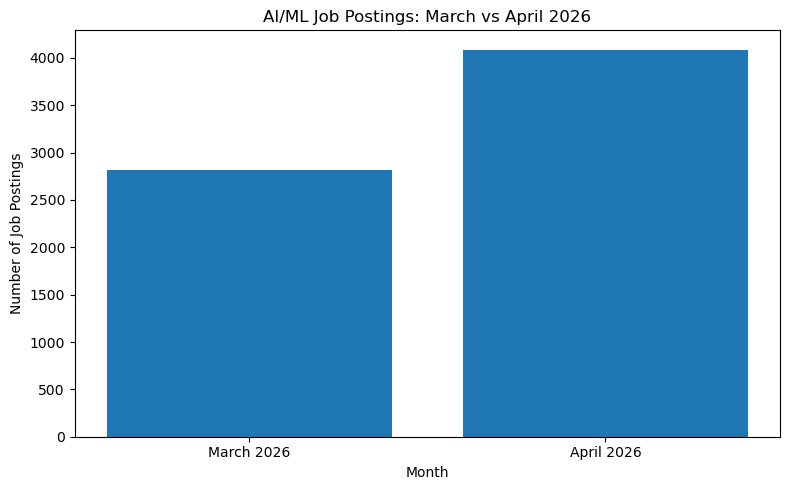

In [40]:
# plot monthly ai/ml job counts
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(
    ["March 2026", "April 2026"],
    [2820, 4087]
)
plt.title("AI/ML Job Postings: March vs April 2026")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.tight_layout()
plt.show()

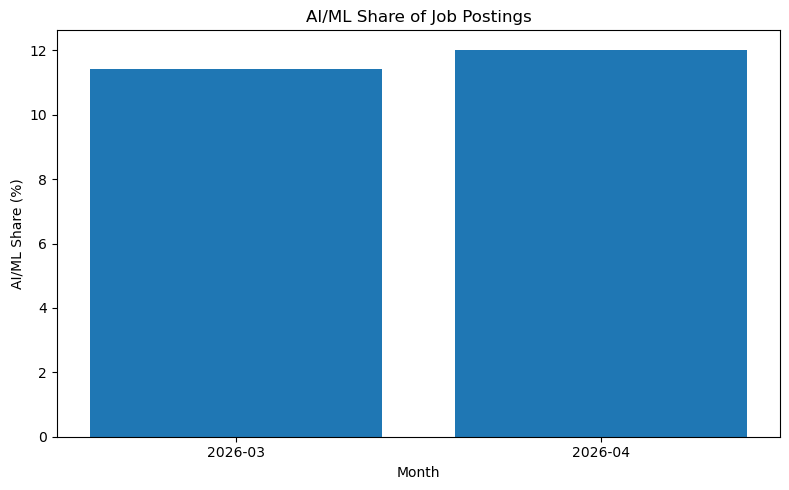

In [41]:
# plot ai/ml share by month
monthly_share = con.execute("""
    select
        period,
        round(
            100.0 * sum(
                case
                    when list_contains(role_families, 'ai_llm_engineer')
                         or list_contains(role_families, 'ml_engineer')
                    then 1 else 0
                end
            ) / count(*),
            2
        ) as ai_ml_share_pct
    from read_parquet('data/unified_core.parquet')
    where period in ('2026-03', '2026-04')
    group by period
    order by period
""").df()

plt.figure(figsize=(8, 5))
plt.bar(monthly_share["period"], monthly_share["ai_ml_share_pct"])
plt.title("AI/ML Share of Job Postings")
plt.xlabel("Month")
plt.ylabel("AI/ML Share (%)")
plt.tight_layout()
plt.show()

In [46]:
# compare skills in AI/LLM and ML job postings

skill_comparison = con.execute("""
WITH roles AS (
    SELECT
        CASE
            WHEN list_contains(role_families, 'ai_llm_engineer')
                 AND NOT list_contains(role_families, 'ml_engineer')
                THEN 'AI/LLM only'
            WHEN list_contains(role_families, 'ml_engineer')
                 AND NOT list_contains(role_families, 'ai_llm_engineer')
                THEN 'ML only'
        END AS role_group,
        skill_themes
    FROM read_parquet('data/unified_core.parquet')
    WHERE period IN ('2026-03', '2026-04')
),
skills AS (
    SELECT DISTINCT
        role_group,
        unnest(skill_themes) AS skill,
        row_number() OVER () AS row_id
    FROM roles
    WHERE role_group IS NOT NULL
),
totals AS (
    SELECT role_group, COUNT(*) AS total_jobs
    FROM roles
    WHERE role_group IS NOT NULL
    GROUP BY role_group
),
counts AS (
    SELECT role_group, skill, COUNT(*) AS jobs
    FROM skills
    GROUP BY role_group, skill
)
SELECT
    c.skill,
    ROUND(100.0 * MAX(CASE WHEN c.role_group = 'AI/LLM only'
        THEN c.jobs END) /
        MAX(CASE WHEN c.role_group = 'AI/LLM only'
        THEN t.total_jobs END), 2) AS ai_llm_pct,
    ROUND(100.0 * MAX(CASE WHEN c.role_group = 'ML only'
        THEN c.jobs END) /
        MAX(CASE WHEN c.role_group = 'ML only'
        THEN t.total_jobs END), 2) AS ml_pct
FROM counts c
JOIN totals t ON c.role_group = t.role_group
GROUP BY c.skill
ORDER BY ai_llm_pct DESC NULLS LAST
""").df()

display(skill_comparison.head(10))

,skill,ai_llm_pct,ml_pct
0,verification,75.99,70.78
1,orchestration,69.99,17.14
2,context_infrastructure,49.27,34.91
3,performance,46.92,43.72
4,mentorship,33.22,25.23
5,process_scaffolding,29.99,20.65
6,legacy_stack,4.73,1.49
7,people_management,1.60,1.78


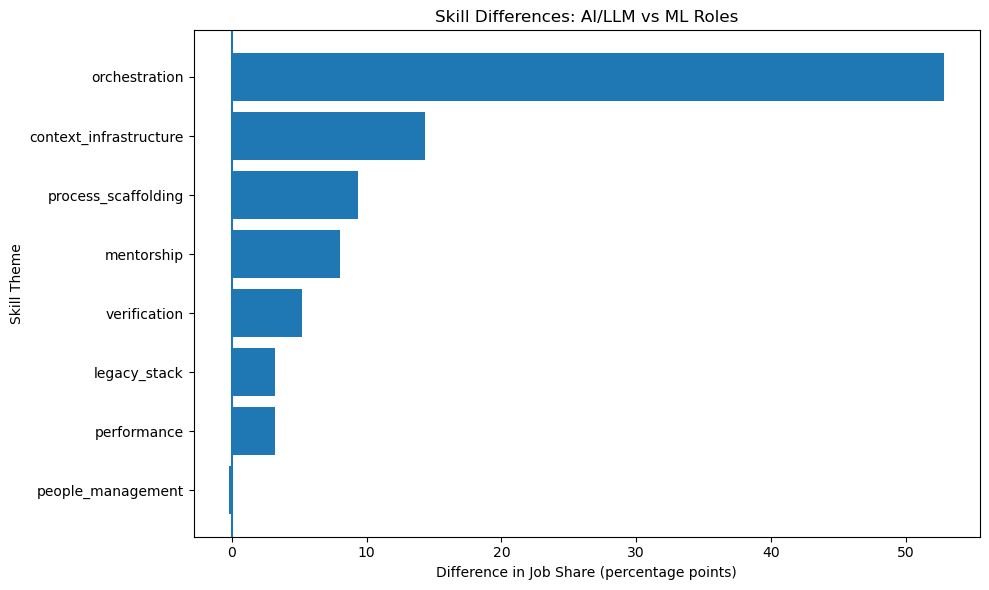

In [47]:
# visualize skill differences between AI/LLM and ML roles

skill_comparison["difference_pp"] = (
    skill_comparison["ai_llm_pct"] - skill_comparison["ml_pct"]
)

plot_data = skill_comparison.sort_values("difference_pp", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_data["skill"], plot_data["difference_pp"])
plt.title("Skill Differences: AI/LLM vs ML Roles")
plt.xlabel("Difference in Job Share (percentage points)")
plt.ylabel("Skill Theme")
plt.axvline(0)
plt.tight_layout()
plt.show()

In [48]:
# identify companies with strong AI/ML hiring representation

company_analysis = con.execute("""
WITH company_jobs AS (
    SELECT
        company_name_canonical,
        COUNT(*) AS total_jobs,
        SUM(
            CASE
                WHEN list_contains(role_families, 'ai_llm_engineer')
                     OR list_contains(role_families, 'ml_engineer')
                THEN 1 ELSE 0
            END
        ) AS ai_ml_jobs
    FROM read_parquet('data/unified_core.parquet')
    WHERE period IN ('2026-03', '2026-04')
      AND NOT is_aggregator
      AND company_name_canonical IS NOT NULL
    GROUP BY company_name_canonical
)
SELECT
    company_name_canonical AS company,
    total_jobs,
    ai_ml_jobs,
    ROUND(100.0 * ai_ml_jobs / total_jobs, 2) AS ai_ml_share_pct
FROM company_jobs
WHERE total_jobs >= 100
ORDER BY ai_ml_share_pct DESC, ai_ml_jobs DESC
LIMIT 15
""").df()

display(company_analysis)

,company,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,Microsoft,296,112.0,37.84
1,Adobe,120,42.0,35.00
2,TikTok,157,54.0,34.39
3,Uber,172,59.0,34.30
4,Capital One,227,77.0,33.92
5,Intuit,144,46.0,31.94
6,Walmart,175,54.0,30.86
7,TikTok USDS Joint Venture,106,30.0,28.30
8,Google,619,158.0,25.53
9,Wells Fargo,222,55.0,24.77


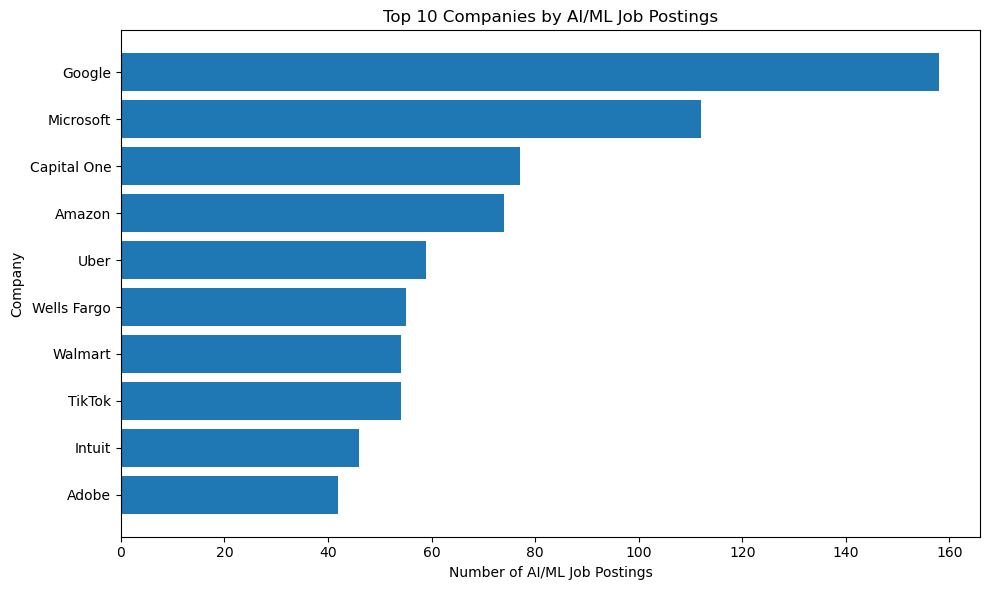

In [49]:
# visualize companies with the highest AI/ML job counts

top_companies = company_analysis.sort_values(
    "ai_ml_jobs", ascending=True
).tail(10)

plt.figure(figsize=(10, 6))
plt.barh(top_companies["company"], top_companies["ai_ml_jobs"])
plt.title("Top 10 Companies by AI/ML Job Postings")
plt.xlabel("Number of AI/ML Job Postings")
plt.ylabel("Company")
plt.tight_layout()
plt.show()

In [50]:
# compare AI/ML hiring share across major metro areas

location_analysis = con.execute("""
WITH metro_jobs AS (
    SELECT
        metro_area,
        COUNT(*) AS total_jobs,
        SUM(
            CASE
                WHEN list_contains(role_families, 'ai_llm_engineer')
                     OR list_contains(role_families, 'ml_engineer')
                THEN 1 ELSE 0
            END
        ) AS ai_ml_jobs
    FROM read_parquet('data/unified_core.parquet')
    WHERE period IN ('2026-03', '2026-04')
      AND metro_area IS NOT NULL
    GROUP BY metro_area
)
SELECT
    metro_area,
    total_jobs,
    ai_ml_jobs,
    ROUND(100.0 * ai_ml_jobs / total_jobs, 2) AS ai_ml_share_pct
FROM metro_jobs
WHERE total_jobs >= 500
ORDER BY ai_ml_share_pct DESC
LIMIT 15
""").df()

display(location_analysis)

,metro_area,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,San Francisco Bay Area,5525,1197.0,21.67
1,Seattle Metro,2501,435.0,17.39
2,Salt Lake City Metro,2416,363.0,15.02
3,New York City Metro,2680,369.0,13.77
4,Dallas-Fort Worth Metro,2870,303.0,10.56
5,Washington DC Metro,3740,388.0,10.37
6,Charlotte Metro,1653,170.0,10.28
7,Boston Metro,2440,237.0,9.71
8,San Diego Metro,774,75.0,9.69
9,Atlanta Metro,1973,185.0,9.38


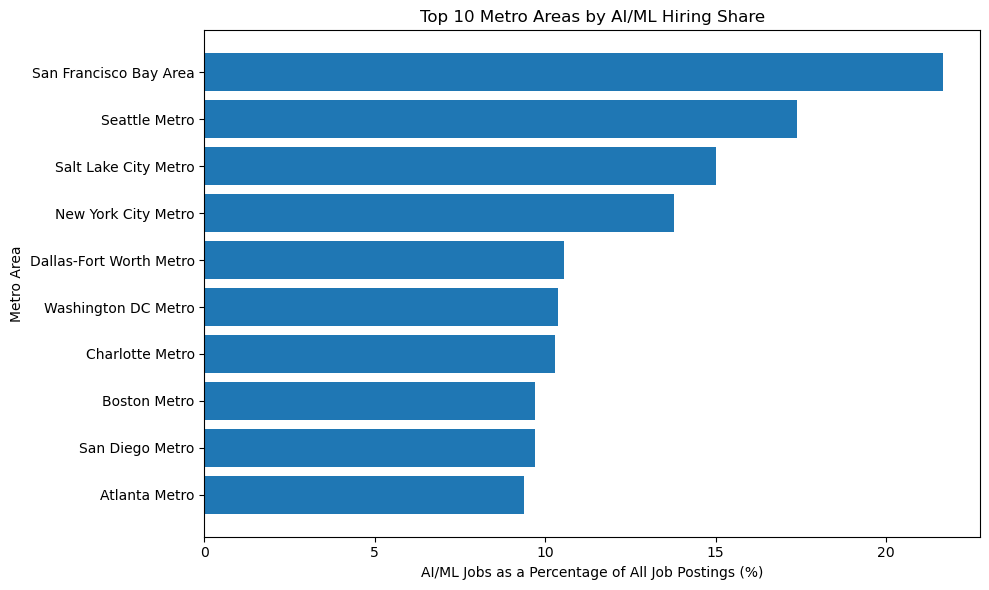

In [51]:
# plot metros with the highest AI/ML job share

top_metros = location_analysis.sort_values(
    "ai_ml_share_pct", ascending=True
).tail(10)

plt.figure(figsize=(10, 6))
plt.barh(top_metros["metro_area"], top_metros["ai_ml_share_pct"])
plt.title("Top 10 Metro Areas by AI/ML Hiring Share")
plt.xlabel("AI/ML Jobs as a Percentage of All Job Postings (%)")
plt.ylabel("Metro Area")
plt.tight_layout()
plt.show()

In [52]:
# export analysis results for the project

monthly_share.to_csv("data/ai_ml_monthly_share.csv", index=False)
skill_comparison.to_csv("data/ai_ml_skill_comparison.csv", index=False)
company_analysis.to_csv("data/ai_ml_company_analysis.csv", index=False)
location_analysis.to_csv("data/ai_ml_location_analysis.csv", index=False)

print("Export complete:")
print("1. data/ai_ml_monthly_share.csv")
print("2. data/ai_ml_skill_comparison.csv")
print("3. data/ai_ml_company_analysis.csv")
print("4. data/ai_ml_location_analysis.csv")

Export complete:
1. data/ai_ml_monthly_share.csv
2. data/ai_ml_skill_comparison.csv
3. data/ai_ml_company_analysis.csv
4. data/ai_ml_location_analysis.csv


In [53]:
# summarize key findings from the analysis

summary = con.execute("""
WITH base AS (
    SELECT
        period,
        list_contains(role_families, 'ai_llm_engineer')
        OR list_contains(role_families, 'ml_engineer') AS is_ai_ml
    FROM read_parquet('data/unified_core.parquet')
    WHERE period IN ('2026-03', '2026-04')
)
SELECT
    period,
    COUNT(*) AS total_jobs,
    COUNT(*) FILTER (WHERE is_ai_ml) AS ai_ml_jobs,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE is_ai_ml) / COUNT(*),
        2
    ) AS ai_ml_share_pct
FROM base
GROUP BY period
ORDER BY period
""").df()

display(summary)

,period,total_jobs,ai_ml_jobs,ai_ml_share_pct
0,2026-03,24716,2820,11.41
1,2026-04,34010,4087,12.02


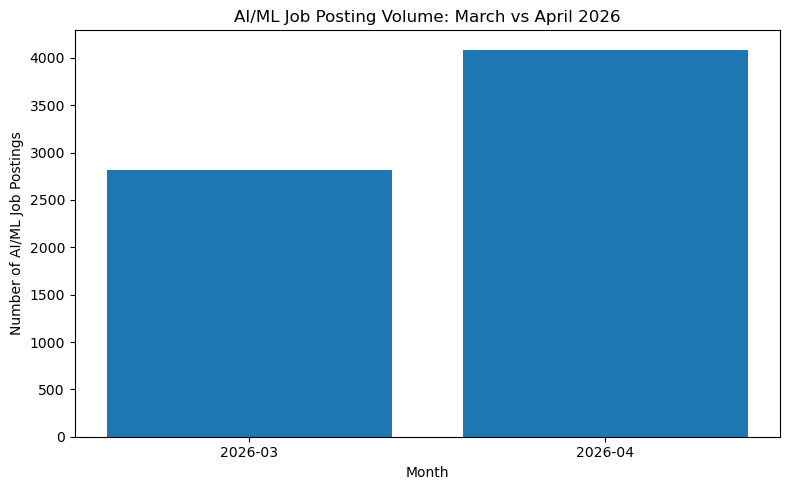

In [54]:
# compare AI/ML job posting counts by month

plt.figure(figsize=(8, 5))
plt.bar(summary["period"], summary["ai_ml_jobs"])
plt.title("AI/ML Job Posting Volume: March vs April 2026")
plt.xlabel("Month")
plt.ylabel("Number of AI/ML Job Postings")
plt.tight_layout()
plt.show()

In [55]:
# verify exported analysis files

from pathlib import Path

output_files = [
    "data/ai_ml_monthly_share.csv",
    "data/ai_ml_skill_comparison.csv",
    "data/ai_ml_company_analysis.csv",
    "data/ai_ml_location_analysis.csv",
]

for file in output_files:
    path = Path(file)
    if path.exists():
        print(f"✅ {file} | {path.stat().st_size:,} bytes")
    else:
        print(f"❌ Missing: {file}")

✅ data/ai_ml_monthly_share.csv | 54 bytes
✅ data/ai_ml_skill_comparison.csv | 385 bytes
✅ data/ai_ml_company_analysis.csv | 460 bytes
✅ data/ai_ml_location_analysis.csv | 567 bytes


In [57]:
# final project findings

print("AI HIRING INTELLIGENCE: KEY FINDINGS")
print("=" * 45)

march = summary.loc[summary["period"] == "2026-03"].iloc[0]
april = summary.loc[summary["period"] == "2026-04"].iloc[0]

job_change = (april["ai_ml_jobs"] / march["ai_ml_jobs"] - 1) * 100
share_change = april["ai_ml_share_pct"] - march["ai_ml_share_pct"]

print(f"\n1. AI/ML postings in March 2026: {march['ai_ml_jobs']:,}")
print(f"2. AI/ML postings in April 2026: {april['ai_ml_jobs']:,}")
print(f"3. Change in AI/ML posting count: {job_change:.2f}%")
print(f"4. Change in AI/ML share: {share_change:+.2f} percentage points")

print("\n5. Skill comparison:")
print(skill_comparison.sort_values(
    "ai_llm_pct", ascending=False
)[["skill", "ai_llm_pct", "ml_pct"]].head(5).to_string(index=False))

print("\n6. Leading companies by AI/ML posting count:")
print(company_analysis.sort_values(
    "ai_ml_jobs", ascending=False
)[["company", "ai_ml_jobs"]].head(5).to_string(index=False))

print("\n7. Leading metros by AI/ML hiring share:")
print(location_analysis.sort_values(
    "ai_ml_share_pct", ascending=False
)[["metro_area", "ai_ml_share_pct"]].head(5).to_string(index=False))

print("\nLimitation: Findings describe this dataset and its March-April 2026 postings,")
print("not necessarily the entire job market.")

AI HIRING INTELLIGENCE: KEY FINDINGS

1. AI/ML postings in March 2026: 2,820
2. AI/ML postings in April 2026: 4,087
3. Change in AI/ML posting count: 44.93%
4. Change in AI/ML share: +0.61 percentage points

5. Skill comparison:
                 skill  ai_llm_pct  ml_pct
          verification       75.99   70.78
         orchestration       69.99   17.14
context_infrastructure       49.27   34.91
           performance       46.92   43.72
            mentorship       33.22   25.23

6. Leading companies by AI/ML posting count:
    company  ai_ml_jobs
     Google       158.0
  Microsoft       112.0
Capital One        77.0
     Amazon        74.0
       Uber        59.0

7. Leading metros by AI/ML hiring share:
             metro_area  ai_ml_share_pct
 San Francisco Bay Area            21.67
          Seattle Metro            17.39
   Salt Lake City Metro            15.02
    New York City Metro            13.77
Dallas-Fort Worth Metro            10.56

Limitation: Findings describe this

In [58]:
# document dataset scope and limitations

dataset_info = con.execute("""
SELECT
    period,
    COUNT(*) AS total_postings,
    COUNT(DISTINCT company_name_canonical) AS unique_companies,
    COUNT(*) FILTER (WHERE metro_area IS NOT NULL) AS postings_with_location
FROM read_parquet('data/unified_core.parquet')
WHERE period IN ('2026-03', '2026-04')
GROUP BY period
ORDER BY period
""").df()

display(dataset_info)

print("\nDATA LIMITATIONS")
print("- March and April 2026 are the main comparison period.")
print("- Posting counts reflect this dataset, not the entire job market.")
print("- Source differences limit comparisons with 2024.")
print("- Remote-work status is not usable as a differentiator in this dataset.")
print("- Skill themes can overlap within a single job posting.")

,period,total_postings,unique_companies,postings_with_location
0,2026-03,24716,6897,19300
1,2026-04,34010,8799,27356



DATA LIMITATIONS
- March and April 2026 are the main comparison period.
- Posting counts reflect this dataset, not the entire job market.
- Source differences limit comparisons with 2024.
- Remote-work status is not usable as a differentiator in this dataset.
- Skill themes can overlap within a single job posting.
